# 10b — Demonstração: vídeos com o esqueleto e a previsão ao vivo

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

Monta os vídeos da demonstração a partir das previsões do notebook **10a**. Para cada vídeo escolhido:

1. tira o vídeo original do ZIP do MINDS-Libras;
2. roda o **MediaPipe Holistic** em todos os quadros, só para desenhar o esqueleto (corpo e mãos);
3. sincroniza o vídeo com os **32 instantes** da série usada pelo modelo (os mesmos índices de amostragem e de recorte do trecho ativo do pipeline);
4. desenha o painel com a **previsão ao vivo**: as 5 palavras mais prováveis depois de observar o trecho do sinal já exibido, e uma linha do tempo com o repouso, o trecho ativo e o **CAM** (onde está a evidência);
5. grava um MP4 por vídeo, uma imagem do último quadro (para slides) e um **vídeo-resumo** com todos os clipes.

**Ressalva para a apresentação:** o recorte do trecho ativo foi feito com o vídeo inteiro, então a previsão ao vivo é uma **simulação** da classificação antecipada, e não um sistema em tempo real.

**Ambiente:** precisa do MediaPipe 0.10.14, que exige numpy < 2. Por isso roda num ambiente separado do TensorFlow (`venv_mp`, kernel `mp_demo`). Tempo: ~10 a 20 minutos para os ~23 vídeos.

## 1. Configuração

In [1]:
import io, os, shutil, tempfile, zipfile, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import mediapipe as mp
import imageio.v2 as imageio
from PIL import Image, ImageDraw, ImageFont
from matplotlib import colormaps

BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
RES = BASE / "resultados"
SAIDA = RES / "10_demo"
ZIPS = BASE.parent / "data" / "minds_malta" / "brutos" / "minds_zip"   # D:\ProjetoMestrado\data\minds_malta\brutos\minds_zip
PASTA_VIDEOS = None            # opcional: pasta com os .mp4 já extraídos (usada no lugar dos ZIPs, se o arquivo existir lá)
VELOCIDADE = 0.75              # 1.0 = velocidade real; 0.75 deixa as barras mais fáceis de acompanhar
PAUSA_FINAL_S = 2.5            # segundos congelados no último quadro, com o resultado
CARTELA_S = 3.0                # duração das cartelas de título do vídeo-resumo
SO_PRIMEIRO = False            # True = gera só o primeiro vídeo (teste rápido)

LARG, ALT = 1920, 1080
VID_W, VID_H, TOPO = 1280, 720, 80
NOMES = {"america": "américa", "maca": "maçã"}
nome = lambda c: NOMES.get(c, c)

# dem = np.load(SAIDA / "previsoes_demo.npz", allow_pickle=False)
dem = np.load(SAIDA / "previsoes_demo.npz", allow_pickle=True)
classes = dem["classes"].astype(str)
n_demo = len(dem["indice"])
print(f"{n_demo} vídeos para montar ({int((dem['tipo'] == 'acerto').sum())} acertos e "
      f"{int((dem['tipo'] == 'erro').sum())} erros) | ZIPs em {ZIPS} | existe: {ZIPS.exists()}")

23 vídeos para montar (20 acertos e 3 erros) | ZIPs em /mnt/d/ProjetoMestrado/data/minds_malta/brutos/minds_zip | existe: True


## 2. Leitura dos vídeos dentro dos ZIPs

Os ZIPs do MINDS maiores que 4 GB têm deslocamentos errados; usamos a mesma função `abrir_zip` do pipeline (`pipeline_keypoints/minds_extrair.py`), que corrige isso.

In [2]:
fonte = (BASE / "pipeline_keypoints" / "minds_extrair.py").read_text(encoding="utf-8")
i = fonte.index("def abrir_zip"); j = fonte.index("\ndef ", i + 10)
ns = {}
exec("import zipfile\nfrom pathlib import Path\n" + fonte[i:j], ns)
abrir_zip = ns["abrir_zip"]
_zips = {}

def ler_video(arquivo):
    # arquivo = 'minds/Sinalizador01.zip/Sinalizador01/Canon/16MedoSinalizador01-1.mp4'
    nome_mp4 = arquivo.split("/")[-1]
    if PASTA_VIDEOS is not None and (Path(PASTA_VIDEOS) / nome_mp4).exists():
        caminho, temporario = Path(PASTA_VIDEOS) / nome_mp4, None
    else:
        partes = arquivo.split("/")
        zip_nome = partes[1]
        dentro = "/".join(partes[2:])
        if zip_nome not in _zips:
            _zips[zip_nome] = abrir_zip(ZIPS / zip_nome)
        temporario = tempfile.NamedTemporaryFile(suffix=".mp4", delete=False)
        temporario.write(_zips[zip_nome].read(dentro)); temporario.close()
        caminho = Path(temporario.name)
    cap = cv2.VideoCapture(str(caminho))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    quadros = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        quadros.append(cv2.resize(f, (VID_W, VID_H), interpolation=cv2.INTER_AREA))
    cap.release()
    if temporario is not None:
        os.unlink(temporario.name)
    return quadros, fps

## 3. Sincronização vídeo ↔ série

O pipeline amostrou **32 quadros uniformes** do vídeo (`floor(linspace(0, n−1, 32))`), detectou o trecho ativo entre os quadros `t0` e `t1` e o reamostrou de volta para 32 instantes. Assim, o instante *j* da série corresponde à posição `t0 + j·(t1 − t0)/31` entre os quadros amostrados, que convertemos para o quadro do vídeo original. Em cada quadro do vídeo, o painel mostra a previsão com os instantes já exibidos.

In [3]:
def quadros_dos_instantes(n_quadros, t0, t1, T=32):
    idx = np.floor(np.linspace(0, n_quadros - 1, T)).astype(int)
    pos = t0 + np.arange(T) * (t1 - t0) / (T - 1)
    a = np.floor(pos).astype(int); b = np.minimum(a + 1, T - 1); fr = pos - a
    return idx[a] + fr * (idx[b] - idx[a])                       # quadro (fracionário) de cada instante

def instantes_vistos(f, quadro_j):
    return int(np.sum(quadro_j <= f))                             # 0..32

_q = quadros_dos_instantes(140, 4, 26)
assert np.all(np.diff(_q) >= 0) and instantes_vistos(0, _q) == 0 and instantes_vistos(139, _q) == 32
print("sincronização conferida; exemplo (140 quadros, t0=4, t1=26): sinal do quadro "
      f"{_q[0]:.0f} ao {_q[-1]:.0f}")

sincronização conferida; exemplo (140 quadros, t0=4, t1=26): sinal do quadro 17 ao 116


## 4. Esqueleto do MediaPipe

In [4]:
mp_hol, mp_draw = mp.solutions.holistic, mp.solutions.drawing_utils
EST_CORPO = mp_draw.DrawingSpec(color=(235, 235, 235), thickness=3, circle_radius=3)
EST_CORPO_L = mp_draw.DrawingSpec(color=(180, 180, 180), thickness=2)
EST_MAO_A = mp_draw.DrawingSpec(color=(40, 170, 255), thickness=2, circle_radius=3)     # BGR: laranja
EST_MAO_B = mp_draw.DrawingSpec(color=(255, 160, 40), thickness=2, circle_radius=3)     # BGR: azul
CORPO_SEM_ROSTO = frozenset((a, b) for a, b in mp_hol.POSE_CONNECTIONS if a > 10 and b > 10)

def desenhar_esqueletos(quadros):
    saida = []
    with mp_hol.Holistic(static_image_mode=False, model_complexity=1, smooth_landmarks=True,
                         min_detection_confidence=0.5, min_tracking_confidence=0.5) as hol:
        for f in quadros:
            r = hol.process(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
            g = f.copy()
            if r.pose_landmarks:
                mp_draw.draw_landmarks(g, r.pose_landmarks, CORPO_SEM_ROSTO, None, EST_CORPO_L)
            for lm, est in ((r.left_hand_landmarks, EST_MAO_A), (r.right_hand_landmarks, EST_MAO_B)):
                if lm:
                    mp_draw.draw_landmarks(g, lm, mp_hol.HAND_CONNECTIONS, est, est)
            saida.append(g)
    return saida

## 5. O painel

- **Topo:** título.
- **Direita:** palavra real, sinalizante (nunca visto pelo modelo), quantos instantes já foram observados e as 5 palavras mais prováveis naquele momento. A barra da palavra correta é verde; as outras, cinza; se a mais provável estiver errada, ela fica vermelha.
- **Embaixo:** linha do tempo do vídeo inteiro. Cinza = repouso (fora da série); a faixa colorida é o trecho ativo com o **CAM** (mais claro = mais evidência) e, acima dela, a curva da probabilidade da palavra correta ao longo do sinal. O cursor branco marca o quadro atual.

In [5]:
def fonte_(tamanho, negrito=False):
    nomes = (["DejaVuSans-Bold.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", "arialbd.ttf"] if negrito
             else ["DejaVuSans.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", "arial.ttf"])
    for n in nomes:
        try:
            return ImageFont.truetype(n, tamanho)
        except OSError:
            pass
    return ImageFont.load_default(size=tamanho)

F_TIT, F_GRANDE, F_MED, F_PEQ, F_MIN = fonte_(34, True), fonte_(44, True), fonte_(26), fonte_(22), fonte_(18)
F_MED_B = fonte_(26, True)
FUNDO, PAINEL, TEXTO, CINZA = (18, 20, 26), (28, 31, 40), (235, 235, 240), (140, 145, 155)
VERDE, VERMELHO, BARRA = (52, 199, 120), (235, 80, 80), (90, 96, 110)
MAGMA = colormaps["magma"]

def painel(quadro_bgr, v, h, f, n_quadros, quadro_j, final=False):
    img = Image.new("RGB", (LARG, ALT), FUNDO)
    img.paste(Image.fromarray(cv2.cvtColor(quadro_bgr, cv2.COLOR_BGR2RGB)), (0, TOPO))
    d = ImageDraw.Draw(img)
    y_real, y_pred = int(dem["y"][v]), int(dem["pred"][v])
    d.text((24, 20), "CNN-1D reconhecendo sinais de Libras a partir do esqueleto (MediaPipe)", font=F_TIT, fill=TEXTO)
    tipo = "ERRO DO MODELO" if dem["tipo"][v] == "erro" else ""
    if tipo:
        d.text((LARG - 330, 22), tipo, font=F_TIT, fill=VERMELHO)

    # painel direito
    x0 = VID_W + 30
    d.rectangle([VID_W, TOPO, LARG, TOPO + VID_H], fill=PAINEL)
    d.text((x0, TOPO + 20), "Sinal real", font=F_PEQ, fill=CINZA)
    d.text((x0, TOPO + 48), nome(classes[y_real]).upper(), font=F_GRANDE, fill=TEXTO)
    d.text((x0, TOPO + 112), f"Sinalizante {int(dem['sinalizante'][v])}: nunca visto no treino", font=F_PEQ, fill=CINZA)
    d.text((x0, TOPO + 140), f"(modelo da rodada {int(dem['rodada'][v])})", font=F_MIN, fill=CINZA)
    d.line([x0, TOPO + 180, LARG - 30, TOPO + 180], fill=BARRA, width=2)
    if h == 0:
        d.text((x0, TOPO + 200), "Aguardando o início do sinal...", font=F_MED, fill=CINZA)
        d.text((x0, TOPO + 240), "(repouso: fora da série)", font=F_PEQ, fill=CINZA)
    else:
        p = dem["prob"][v][h - 1]
        d.text((x0, TOPO + 196), f"Previsão com {h} de 32 instantes ({100 * h / 32:.0f}% do sinal)", font=F_PEQ, fill=TEXTO)
        top = np.argsort(-p)[:5]
        larg_max = LARG - x0 - 40
        for i, c in enumerate(top):
            yb = TOPO + 235 + i * 66
            cor = VERDE if c == y_real else (VERMELHO if i == 0 else BARRA)
            d.text((x0, yb), nome(classes[c]), font=F_MED_B if i == 0 else F_MED, fill=TEXTO)
            d.text((LARG - 40, yb), f"{100 * p[c]:.0f}%", font=F_MED, fill=TEXTO, anchor="ra")
            d.rectangle([x0, yb + 36, x0 + larg_max, yb + 58], fill=(45, 49, 60))
            d.rectangle([x0, yb + 36, x0 + max(2, int(larg_max * p[c])), yb + 58], fill=cor)
        if final:
            ok = y_pred == y_real
            msg = f"Resultado: {'ACERTOU' if ok else 'ERROU'} ({nome(classes[y_pred])}, {100 * p[y_pred]:.0f}%)"
            d.rectangle([x0 - 10, TOPO + VID_H - 90, LARG - 20, TOPO + VID_H - 30], fill=VERDE if ok else VERMELHO)
            d.text((x0 + 4, TOPO + VID_H - 76), msg, font=F_MED_B, fill=(15, 15, 15))
            dec = int(dem["decisao"][v])
            d.text((x0, TOPO + VID_H - 130), f"Resposta estável a partir de {100 * dec / 32:.0f}% do sinal",
                   font=F_PEQ, fill=CINZA)

    # linha do tempo
    ly0, lx0, lx1 = TOPO + VID_H + 20, 40, LARG - 40
    escala = lambda q: lx0 + (lx1 - lx0) * q / max(1, n_quadros - 1)
    xa, xb = escala(quadro_j[0]), escala(quadro_j[-1])
    d.text((lx0, ly0), "Linha do tempo do vídeo", font=F_PEQ, fill=TEXTO)
    d.text((lx1, ly0), "cinza = repouso  |  faixa colorida = sinal (CAM: mais claro = mais evidência)",
           font=F_MIN, fill=CINZA, anchor="ra")
    # curva da probabilidade da palavra correta
    cy0, cy1 = ly0 + 40, ly0 + 140
    d.rectangle([lx0, cy0, lx1, cy1], fill=(24, 27, 34))
    d.line([lx0, cy0 + (cy1 - cy0) / 2, lx1, cy0 + (cy1 - cy0) / 2], fill=(40, 44, 54), width=1)
    d.text((lx0 + 6, cy0 + 4), f"P({nome(classes[y_real])})", font=F_MIN, fill=VERDE)
    if h >= 1:
        pts = [(escala(quadro_j[j]), cy1 - (cy1 - cy0) * float(dem["prob"][v][j][y_real])) for j in range(h)]
        if len(pts) > 1:
            d.line(pts, fill=VERDE, width=4)
        d.ellipse([pts[-1][0] - 6, pts[-1][1] - 6, pts[-1][0] + 6, pts[-1][1] + 6], fill=VERDE)
    # faixa do CAM
    fy0, fy1 = cy1 + 12, cy1 + 52
    d.rectangle([lx0, fy0, lx1, fy1], fill=(70, 74, 84))
    camv = dem["cam"][v]
    for j in range(32):
        xa_j = escala(quadro_j[j] - (quadro_j[1] - quadro_j[0]) / 2 if j else quadro_j[0])
        xb_j = escala(quadro_j[j] + (quadro_j[-1] - quadro_j[-2]) / 2 if j < 31 else quadro_j[-1])
        r, g, b, _ = MAGMA(0.15 + 0.85 * float(camv[j]))
        d.rectangle([xa_j, fy0, xb_j, fy1], fill=(int(255 * r), int(255 * g), int(255 * b)))
    d.text(((xa + xb) / 2, fy1 + 6), "sinal: 32 instantes", font=F_MIN, fill=CINZA, anchor="ma")
    xm = escala(quadro_j[15] + (quadro_j[16] - quadro_j[15]) / 2)
    d.line([xm, cy0, xm, fy1], fill=(120, 120, 130), width=1)
    d.text((xm + 4, cy1 - 22), "50%", font=F_MIN, fill=(150, 150, 160))
    # cursor
    xc = escala(f)
    d.line([xc, cy0 - 4, xc, fy1 + 4], fill=(255, 255, 255), width=3)
    return np.asarray(img)

## 6. Cartelas do vídeo-resumo

In [6]:
def cartela(titulo, linhas, cor_titulo=TEXTO):
    img = Image.new("RGB", (LARG, ALT), FUNDO)
    d = ImageDraw.Draw(img)
    d.text((LARG / 2, 330), titulo, font=fonte_(60, True), fill=cor_titulo, anchor="ma")
    for i, l in enumerate(linhas):
        d.text((LARG / 2, 450 + i * 52), l, font=F_MED, fill=CINZA, anchor="ma")
    return np.asarray(img)

INTRO = cartela("Reconhecimento de sinais de Libras com uma CNN-1D",
    ["Cada vídeo vira uma série temporal: 32 instantes × 321 coordenadas do esqueleto (MediaPipe).",
     "Cada vídeo é de uma pessoa que o modelo NUNCA viu no treino (divisão por sinalizante).",
     "As barras mostram a previsão ao vivo, só com o trecho do sinal já exibido.",
     "Base MINDS-Libras: 20 palavras, 12 sinalizantes. F1 macro no teste: ~91%."])
CART_ACERTOS = cartela("Uma palavra de cada", [f"{int((dem['tipo'] == 'acerto').sum())} sinais, sinalizantes diferentes"])
CART_ERROS = cartela("Onde o modelo erra", ["Erros mais confiantes do modelo, em sinalizantes nunca vistos",
                                             "(ex.: medo × filho têm locação e movimento parecidos)"], VERMELHO)

## 7. Gerar os vídeos

In [7]:
CLIPES = SAIDA / "clipes"; CLIPES.mkdir(exist_ok=True)
def escritor(caminho, fps):
    return imageio.get_writer(caminho, fps=fps, codec="libx264", quality=7, macro_block_size=8)

ordem = list(range(n_demo)) if not SO_PRIMEIRO else [0]
fps_saida = 30 * VELOCIDADE
resumo = escritor(SAIDA / "demo_resumo.mp4", fps_saida)
for q in [INTRO] * int(CARTELA_S * fps_saida):
    resumo.append_data(q)
ja_erros = False
registros = []
for n_feito, v in enumerate(ordem, 1):
    if dem["tipo"][v] == "acerto" and n_feito == 1:
        for q in [CART_ACERTOS] * int(CARTELA_S * fps_saida):
            resumo.append_data(q)
    if dem["tipo"][v] == "erro" and not ja_erros:
        for q in [CART_ERROS] * int(CARTELA_S * fps_saida):
            resumo.append_data(q)
        ja_erros = True
    arq = str(dem["arquivo"][v])
    quadros, fps = ler_video(arq)
    quadros = desenhar_esqueletos(quadros)
    n = len(quadros)
    qj = quadros_dos_instantes(n, int(dem["t0"][v]), int(dem["t1"][v]))
    palavra = nome(classes[int(dem["y"][v])])
    nome_clipe = f"{n_feito:02d}_{dem['tipo'][v]}_{palavra}_S{int(dem['sinalizante'][v]):02d}"
    clipe = escritor(CLIPES / f"{nome_clipe}.mp4", fps * VELOCIDADE)
    for f in range(n):
        tela = painel(quadros[f], v, instantes_vistos(f, qj), f, n, qj)
        clipe.append_data(tela); resumo.append_data(tela)
    tela = painel(quadros[-1], v, 32, n - 1, n, qj, final=True)
    meio = int(round(qj[20]))                     # quadro no meio do gesto, para a imagem dos slides
    Image.fromarray(painel(quadros[meio], v, 32, meio, n, qj, final=True)).save(CLIPES / f"{nome_clipe}.png")
    for _ in range(int(PAUSA_FINAL_S * fps * VELOCIDADE)):
        clipe.append_data(tela); resumo.append_data(tela)
    clipe.close()
    registros.append(dict(clipe=nome_clipe, quadros=n, fps=round(fps, 2), duracao_s=round(n / fps / VELOCIDADE + PAUSA_FINAL_S, 1)))
    print(f"[{n_feito}/{len(ordem)}] {nome_clipe}: {n} quadros", flush=True)
resumo.close()
display(pd.DataFrame(registros))
print("vídeo-resumo:", SAIDA / "demo_resumo.mp4")

Sinalizador09.zip: 124 deslocamentos corrigidos


I0000 00:00:1795697654.991321    9338 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1795697655.029244    9443 gl_context.cc:357] GL version: 3.0 (OpenGL ES 3.0 Mesa 23.2.1-1ubuntu3.1~22.04.4), renderer: D3D12 (Intel(R) UHD Graphics)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


W0000 00:00:1795697655.318678    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795697655.387925    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795697655.396603    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795697655.397538    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


W0000 00:00:1795697655.567863    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795697655.575103    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795697655.662702    9431 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795697655.686729    9432 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


/home/magnusfelinto/venv_mp/lib/python3.10/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


[1/23] 01_acerto_acontecer_S09: 150 quadros


... (51 outputs left out)

I0000 00:00:1795698377.230437    9338 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1795698377.239890   12877 gl_context.cc:357] GL version: 3.0 (OpenGL ES 3.0 Mesa 23.2.1-1ubuntu3.1~22.04.4), renderer: D3D12 (Intel(R) UHD Graphics)
W0000 00:00:1795698377.306230   12875 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795698377.329865   12874 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795698377.331671   12875 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795698377.331830   12874 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0

[23/23] 23_erro_medo_S01: 150 quadros


,clipe,quadros,fps,duracao_s
0,01_acerto_acontecer_S09,150,30.17,9.1
1,02_acerto_aluno_S02,122,30.25,7.9
2,03_acerto_amarelo_S01,162,30.19,9.7
3,04_acerto_américa_S09,191,30.13,11.0
4,05_acerto_aproveitar_S01,116,30.26,7.6
5,06_acerto_bala_S05,137,30.22,8.5
6,07_acerto_banco_S12,138,30.22,8.6
7,08_acerto_banheiro_S10,104,30.29,7.1
8,09_acerto_barulho_S02,125,30.24,8.0
9,10_acerto_cinco_S11,147,30.20,9.0


vídeo-resumo: /mnt/d/ProjetoMestrado/trabalho_series_temporais/resultados/10_demo/demo_resumo.mp4


## 8. Prévia do último quadro de alguns clipes

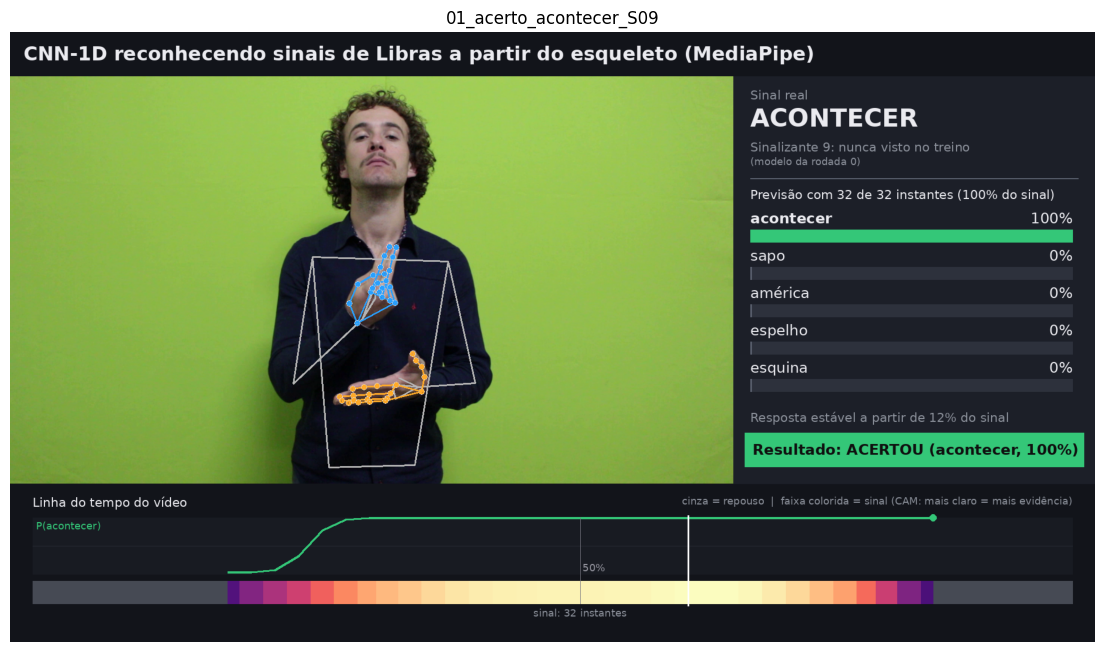

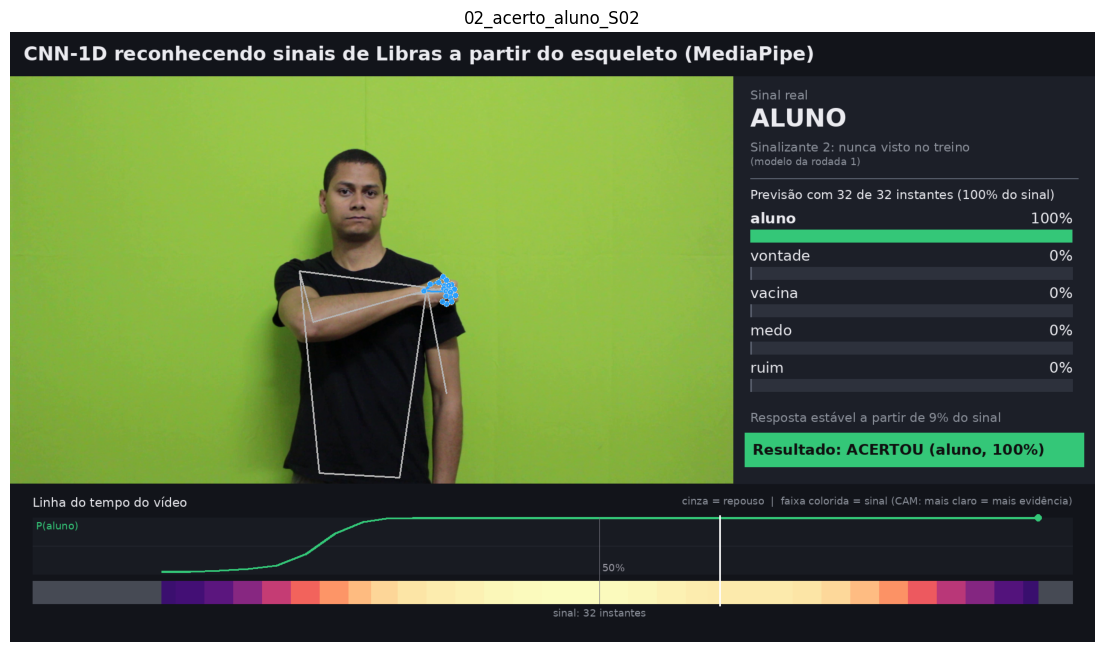

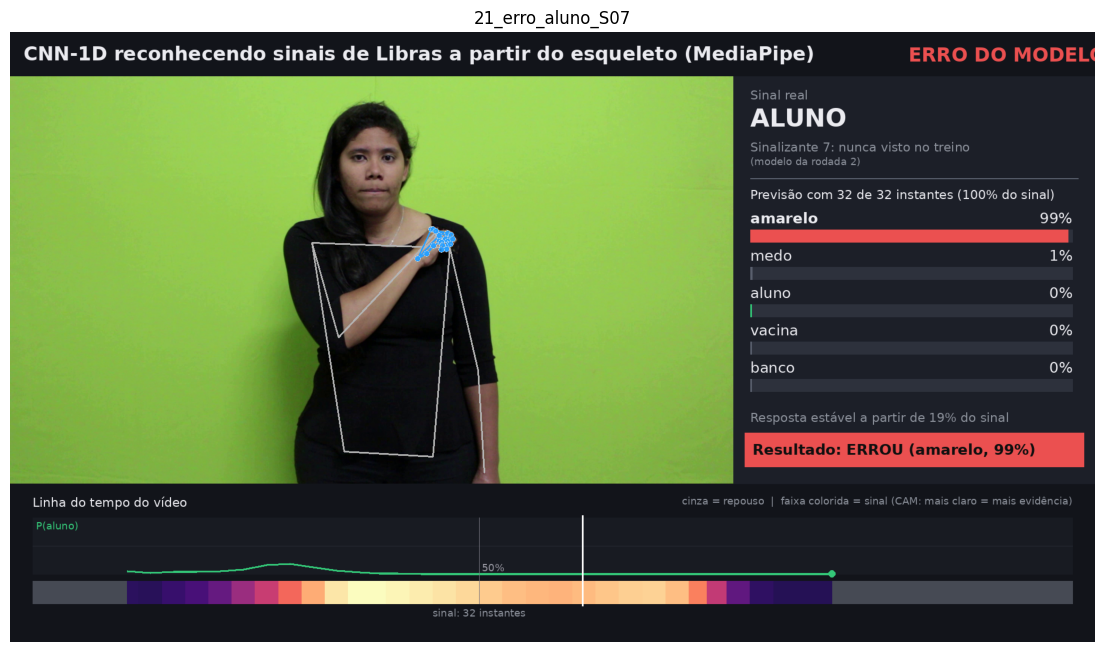

In [8]:
import matplotlib.pyplot as plt
pngs = sorted(CLIPES.glob("*.png"))[:2] + sorted(CLIPES.glob("*erro*.png"))[:1]
for p in pngs:
    plt.figure(figsize=(14, 8)); plt.imshow(Image.open(p)); plt.axis("off"); plt.title(p.stem); plt.show()